# An ergodic target that only expands: the 2-DoF peg-slide toy

The 6-DoF `peg_slide` task in the plane, with the law of `run_ergodic_expansion_6dof.py`.

- The robot controls the peg tip $s = (x, y)$: $x$ towards the goal, $y$ up.
- The **environment** is a free-standing block with a narrow slot, open at the top. A barrier beside the block keeps it
  in place. Once the peg is at the slot's bottom the barrier is removed, and pushing a slot wall slides the block along.
- The **demonstration** is clicked into the world (Section 3): a master trajectory, and the datapoints of the target.
- The **law** is the arm's own: the `ExpandingErgodicController` that `run_ergodic_expansion_6dof.py` runs, imported
  and run on two axes. Nothing of it is rewritten here.

The task is done when the peg and the block are both at the goal: the peg's $x$ and the block's centre beyond 8.2.

In [189]:
import contextlib
import io
import math
import multiprocessing
import sys
from concurrent.futures import ProcessPoolExecutor
from dataclasses import dataclass
from pathlib import Path

import numpy as np
from IPython.display import HTML, display
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.axes import Axes
from matplotlib.collections import LineCollection
from matplotlib.figure import Figure

# The kernel runs beside ergodic_controller.py, which would shadow the package of that name.
sys.path[:] = [p for p in sys.path if Path(p or ".").resolve() != Path.cwd()]

## 1. The law: the arm's own

`ExpandingErgodicController` of `phase_ergodic_controller.py`, the object `run_ergodic_expanding.py` and
`run_ergodic_expansion_6dof.py` build, with the same arguments: a `PhaseTask`, $u_{\max}$, the forgetting window, the
front share 0.25 and $K = 10$. Its `step` takes the measured cube state and returns the next commanded one. Inside it are
the phase estimate and its on-reference rule, the target weights, the forgetting statistic, the gradient through
$\Lambda$'s tensor train (rounded to $10^{-2}$, as on the arm), the pull back from the cube's faces and the clip.

The notebook supplies only what the arm's scripts supply: the task in the cube (Section 4), and the plant.

`density` is for the figures alone: the $K \times K$ cosine series of a set of weighted points, which is how the law
sees both the target and the stored trajectory.

In [190]:
from ergodic_controller.phase_ergodic_controller import ExpandingErgodicController, PhaseTask

K = 10  # ERGODIC_K of live_ergodic_controller.py
FRONT_SHARE = 0.25  # as run_ergodic_expanding.py
FORGET_PROGRESS = 75.0  # as run_ergodic_expanding.py


def density(
    Z: np.ndarray,  # (P, 2) cube points
    a: np.ndarray,  # (P,) their weights
    grid: np.ndarray,  # (G,) cube coordinates, used on both axes
) -> np.ndarray:  # (G, G), indexed [y, x]
    """The density of sum_p a_p delta(z - z_p) as the law sees it: its K x K cosine series."""
    k = np.arange(K)
    W = (np.cos(np.pi * Z[:, :1] * k) * a[:, None]).T @ np.cos(np.pi * Z[:, 1:] * k)
    B = np.cos(np.pi * grid[:, None] * k) / np.where(k == 0, 1.0, 0.5)
    return (B @ W @ B.T).T


# The series of one point has that point's mass and, truncated at K, peaks within 0.01 of it.
_grid = np.linspace(0.0, 1.0, 201)
_d = density(np.array([[0.3, 0.7]]), np.array([1.0]), _grid)
_iy, _ix = np.unravel_index(_d.argmax(), _d.shape)
assert math.isclose(np.trapezoid(np.trapezoid(_d, _grid), _grid), 1.0)
assert abs(_grid[_ix] - 0.3) < 0.01 and abs(_grid[_iy] - 0.7) < 0.01

## 2. The environment

World units, on a $10 \times 10$ square; the cube of the Fourier basis is $z = s / 10$. The peg is its tip, a point
with the peg's half-width of 0.1 taken off every gap.

- The **block** is $1.5$ wide and $2$ high, with its centre $c$ at $c_0 = 2.3$. Its **slot** is open at the top, 1.5 deep,
  and leaves the tip $\pm 0.2$ of play. The block is solid to the tip everywhere else: a tip that would enter it slides
  along its face instead.
- The **barrier** is a wall at $x = 4$. It stops the tip, and it stops the block after 0.95 of travel.
- With the tip within 0.15 of the slot's bottom the barrier is **removed**, for the rest of the run. A tip in the slot
  that is pushed against a wall takes the block with it, as far as the **goal**, 6 units from $c_0$.

The block moves only when pushed from inside the slot. `Slide(home)` starts the block somewhere else than where it was
taught, as a peg mounted off its modelled place does; the goal stays where it is.

In [191]:
SIZE = 10.0  # the world's side, and world units per cube unit
PEG_HALF, SLOT_HALF, BLOCK_HALF = 0.1, 0.3, 0.75
CLEARANCE = SLOT_HALF - PEG_HALF  # the tip's play to either side of the slot's centre
BLOCK_BOTTOM, BLOCK_TOP = 1.0, 3.0
SLOT_FLOOR = 1.5
INSERTED = 0.15  # the tip this close to the slot's floor removes the barrier
BARRIER_X, BARRIER_Y = 4.0, (0.5, 8.0)
C0 = 2.3  # the block's centre as taught
TRAVEL = 6.0  # from there to the goal
GOAL_C = C0 + TRAVEL  # the block's centre at the goal, wherever it started
GOAL_X = GOAL_C - 0.1  # the peg and the block's centre both beyond this is the task done


@dataclass
class Slide:
    home: float = C0  # the block's centre at the start
    c: float | None = None  # the block's centre now
    barrier: bool = True

    def __post_init__(self) -> None:
        if self.c is None:
            self.c = self.home


def in_slot(c: float, x: float, y: float) -> bool:
    # The margin keeps a tip that was clamped to a slot wall inside, whatever the rounding.
    return abs(x - c) <= CLEARANCE + 1e-9 and SLOT_FLOOR <= y < BLOCK_TOP


def free(world: Slide, s: np.ndarray, x: float, y: float) -> bool:
    """Whether the tip can move from s (2,) to (x, y): not into the block, not through the barrier."""
    in_block = abs(x - world.c) < BLOCK_HALF + PEG_HALF and BLOCK_BOTTOM < y < BLOCK_TOP
    crosses = (s[0] - BARRIER_X) * (x - BARRIER_X) < 0 and BARRIER_Y[0] <= y <= BARRIER_Y[1]
    return (not in_block or in_slot(world.c, x, y)) and not (world.barrier and crosses)


def slide_step(
    world: Slide,
    s: np.ndarray,  # (2,) the tip now
    s_new: np.ndarray,  # (2,) the tip commanded
) -> np.ndarray:  # (2,)
    """The tip the environment lets the robot reach from s; moves the block if it is pushed."""
    nx, ny = np.clip(s_new, 0.0, SIZE)
    if not (in_slot(world.c, *s) and ny < BLOCK_TOP):
        # Outside the slot, or leaving it through the top: stopped faces let the tip slide along them.
        for x, y in ((nx, ny), (nx, s[1]), (s[0], ny)):
            if free(world, s, x, y):
                return np.array([x, y])
        return np.array(s)
    ny = max(ny, SLOT_FLOOR)
    if ny <= SLOT_FLOOR + INSERTED:
        world.barrier = False
    stop = min(GOAL_C, BARRIER_X - BLOCK_HALF) if world.barrier else GOAL_C
    pushed = nx - np.clip(nx, world.c - CLEARANCE, world.c + CLEARANCE)
    world.c = float(np.clip(world.c + pushed, world.home, max(stop, world.c)))
    return np.array([np.clip(nx, world.c - CLEARANCE, world.c + CLEARANCE), ny])


def draw_world(ax: Axes, world: Slide) -> None:
    """The block with its slot, the barrier while it stands, and the goal."""
    c = world.c
    # Two walls and a floor, so that a density drawn underneath shows in the slot.
    for lo, hi, top in (
        (c - BLOCK_HALF, c - SLOT_HALF, BLOCK_TOP),
        (c + SLOT_HALF, c + BLOCK_HALF, BLOCK_TOP),
        (c - SLOT_HALF, c + SLOT_HALF, SLOT_FLOOR),
    ):
        ax.fill_between([lo, hi], BLOCK_BOTTOM, top, color="0.75", lw=0, zorder=2)
    if world.barrier:
        ax.plot([BARRIER_X, BARRIER_X], BARRIER_Y, ":g", lw=3, label="barrier")
    ax.fill(
        [GOAL_C + 0.3, GOAL_C + 0.3, GOAL_C + 1.0],
        [SLOT_FLOOR - 0.4, SLOT_FLOOR + 0.6, SLOT_FLOOR + 0.1],
        color="gold",
        label="goal",
    )
    ax.set(xlim=(0, SIZE), ylim=(0, SIZE), aspect="equal", xlabel="x", ylabel="y")


# Small tests of the step.
_w = Slide()
_s = slide_step(
    _w, np.array([2.0, 3.02]), np.array([2.03, 2.9])
)  # on the block's top: slides along it
assert tuple(_s) == (2.03, 3.02)
_s = slide_step(_w, np.array([1.42, 2.0]), np.array([1.47, 2.1]))  # against its side: slides up it
assert tuple(_s) == (1.42, 2.1)
assert slide_step(_w, np.array([2.4, 3.02]), np.array([2.4, 2.9]))[1] == 2.9  # into the slot
_s = slide_step(_w, np.array([3.98, 2.0]), np.array([4.03, 2.0]))  # the barrier stops the tip
assert _s[0] == 3.98
_over = BARRIER_Y[1] + 0.1
assert (
    slide_step(_w, np.array([3.98, _over]), np.array([4.03, _over]))[0] == 4.03
)  # but not above it
_s = slide_step(
    _w, np.array([2.45, 2.5]), np.array([4.5, 2.5])
)  # and the block, pushed from inside
assert (
    math.isclose(_w.c, BARRIER_X - BLOCK_HALF)
    and math.isclose(_s[0], _w.c + CLEARANCE)
    and _w.barrier
)
_s = slide_step(_w, _s, np.array([_s[0], 0.5]))  # the slot's floor: the barrier is removed
assert _s[1] == SLOT_FLOOR and not _w.barrier
_s = slide_step(_w, _s, np.array([_s[0] + 1.0, 1.6]))  # so the block goes on
assert math.isclose(_w.c, BARRIER_X - BLOCK_HALF + 1.0) and math.isclose(_s[0], _w.c + CLEARANCE)
_s = slide_step(_w, _s, np.array([20.0, 1.6]))  # as far as the goal
assert _w.c == GOAL_C
_s = slide_step(_w, _s, np.array([_s[0], 3.5]))  # lifted out: free again, the block left behind
assert _s[1] == 3.5 and _w.c == GOAL_C and not _w.barrier
print("environment tests passed")

environment tests passed


## 3. Teaching by clicks

As on the arm, there are two demonstrations:

- the **master**: click the waypoints of one successful execution, in order. Start above the slot, go down to its
  bottom, then straight to the goal, as the block will carry the peg. The master is the polyline through the clicks.
- the **datapoints**: click every place the peg may have to be, one click a datapoint. A region is weighted by how
  many datapoints it got, so click more where the task needs care, as `teach_datapoints.py` is used.

**Left click** adds a point, **right click** withdraws the last one. A click is taken anywhere, on the block and in its slot too: the
block moves, so a place it covers now is free later. The zoom and
pan tools take the mouse while they are selected. The first cell loads the last saved set, so a session extends it;
set `MASTER_CLICKS = []` or `DATA_CLICKS = []` to start one over.

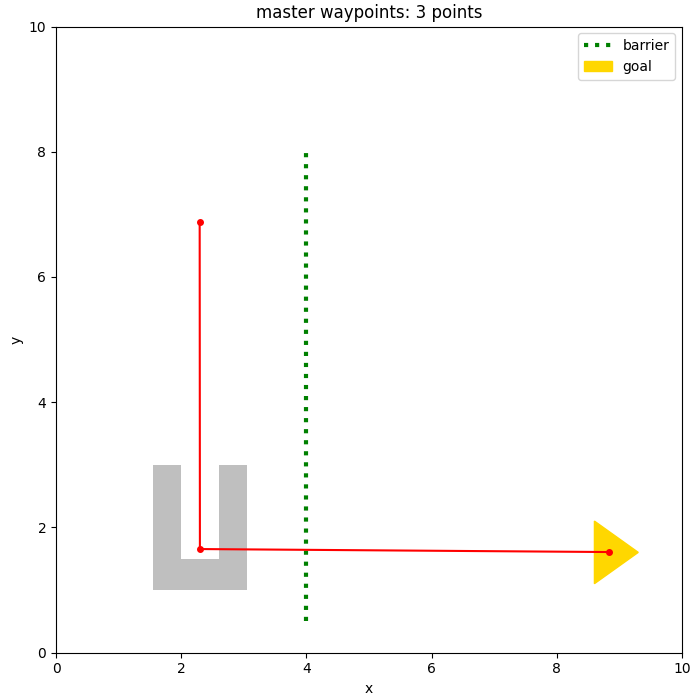

In [192]:
%matplotlib widget

TEACH_FILE = Path("../../output/peg_slide_2D_teaching.npz")
MASTER_CLICKS, DATA_CLICKS = [], []
if TEACH_FILE.exists():
    _saved = np.load(TEACH_FILE)
    MASTER_CLICKS = [tuple(p) for p in _saved["master"]]
    DATA_CLICKS = [tuple(p) for p in _saved["datapoints"]]


def teach(clicks: list[tuple[float, float]], title: str, style: str) -> Figure:
    """A figure of the taught environment that adds its clicks to the list, wherever they are."""
    fig, ax = plt.subplots(figsize=(7, 7), layout="constrained")
    draw_world(ax, Slide())
    if clicks is not MASTER_CLICKS and MASTER_CLICKS:
        ax.plot(*np.array(MASTER_CLICKS).T, "-r", lw=1, label="master")
    (drawn,) = ax.plot([], [], style, ms=4)
    ax.legend(loc="upper right")

    def redraw() -> None:
        drawn.set_data(*np.array(clicks).reshape(-1, 2).T)
        ax.set_title(f"{title}: {len(clicks)} points")
        fig.canvas.draw_idle()

    def on_click(event) -> None:
        if event.inaxes is not ax or ax.get_navigate_mode():
            return
        if event.button == 3 and clicks:
            clicks.pop()
        elif event.button == 1:
            clicks.append((event.xdata, event.ydata))
        redraw()

    fig.canvas.mpl_connect("button_press_event", on_click)
    redraw()
    return fig


master_figure = teach(MASTER_CLICKS, "master waypoints", "o-r")

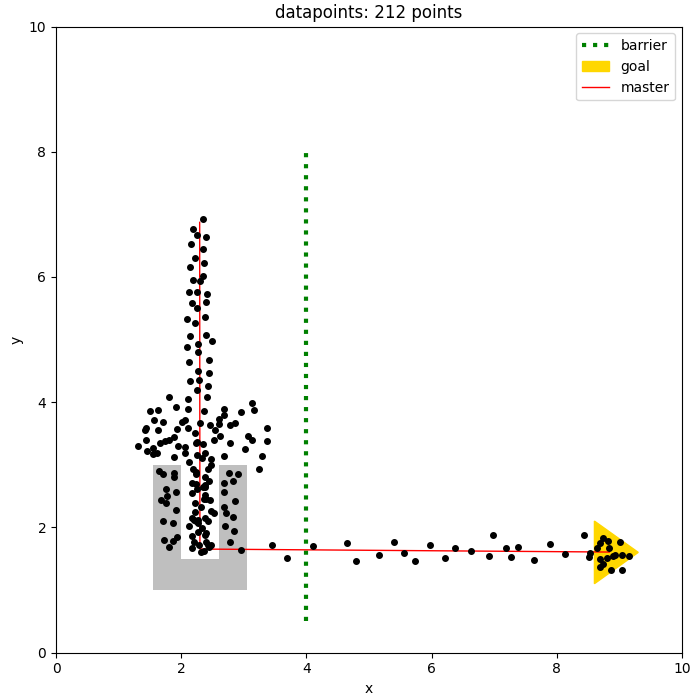

In [193]:
datapoint_figure = teach(DATA_CLICKS, "datapoints", "ok")

In [194]:
np.savez(TEACH_FILE, master=np.array(MASTER_CLICKS), datapoints=np.array(DATA_CLICKS))
print(f"{len(MASTER_CLICKS)} master waypoints and {len(DATA_CLICKS)} datapoints in {TEACH_FILE}")

3 master waypoints and 212 datapoints in ../../output/peg_slide_2D_teaching.npz


## 4. Master, cloud and derived numbers

- The **master** is the clicked polyline at 401 samples equally spaced in arc length, so $\varphi$ is its normalised arc length.
- The **cloud** is the datapoints, each with the phase of the master sample nearest to it.

| quantity | value | source |
|---|---|---|
| $h$ | median distance to the $k$-th nearest datapoint, $k = \mathrm{round}(\sqrt N)$ | the cloud |
| $\sigma_f = h / \ell$ | the cloud's resolution as a phase | the cloud and the master's length $\ell$ |
| on-reference distance $= h$ | how near something taught the peg must be for $\varphi$ to advance | as `live_ergodic_controller.py` |
| forgetting window $= 75\, h / v_{\max}$ | steps the statistic remembers: 75 times what $h$ takes at the commanded speed | `run_ergodic_expanding.py` |

These are handed to the law as a `PhaseTask` on two axes, with the world's side as metres per cube unit.

master: 3 waypoints, length 11.76; cloud: 212 datapoints
k = 15, h = 0.449, sigma_f = 0.0382
forgetting over 841 steps


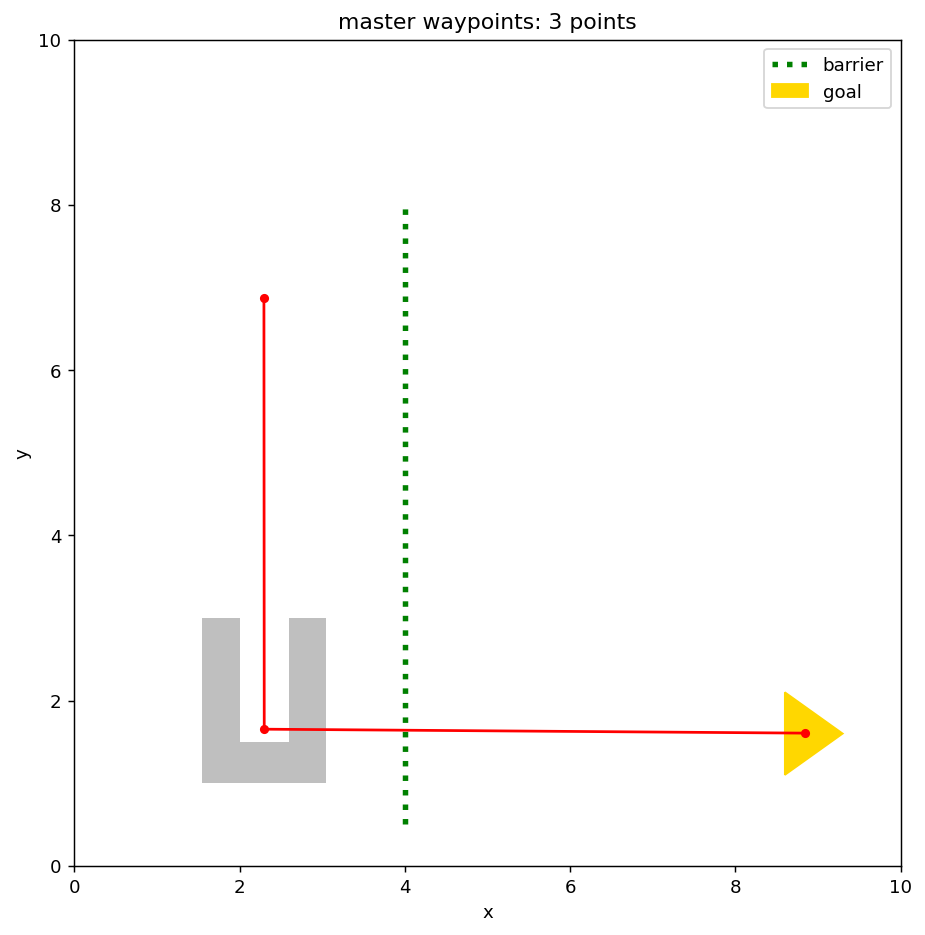

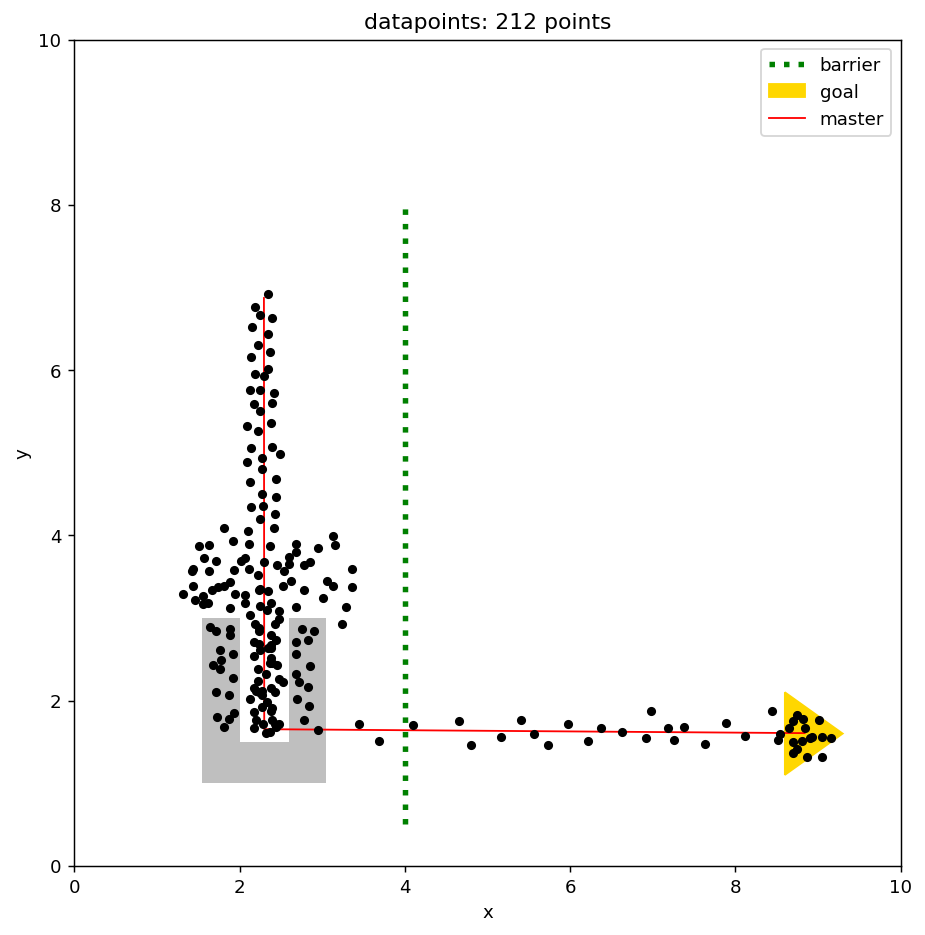

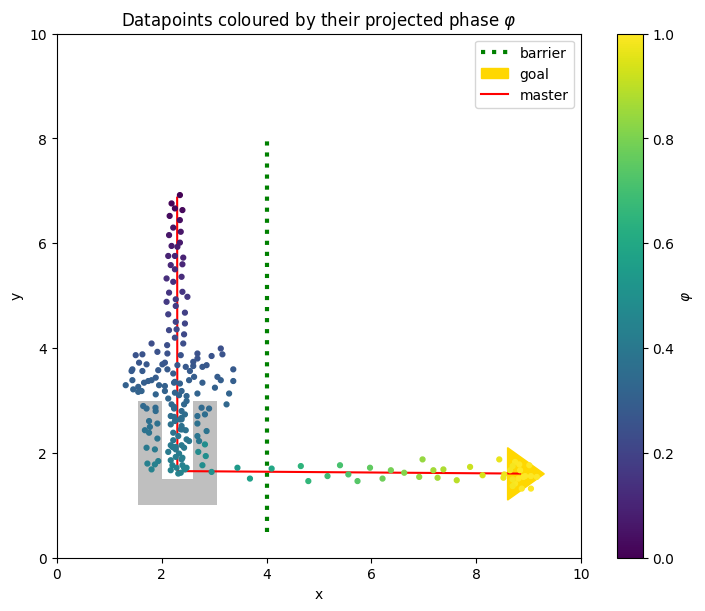

In [195]:
%matplotlib inline

assert len(MASTER_CLICKS) >= 2, "click at least two master waypoints in Section 3"
assert len(DATA_CLICKS) >= 10, "click at least ten datapoints in Section 3"

PHI_GRID = np.linspace(0.0, 1.0, 401)
_way = np.array(MASTER_CLICKS)
_arc = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(_way, axis=0), axis=1))])
LENGTH = _arc[-1]
MASTER = np.column_stack(
    [np.interp(PHI_GRID * LENGTH, _arc, _way[:, i]) for i in range(2)]
)  # (401, 2)
CLOUD = np.array(DATA_CLICKS)  # (N, 2)
PHI_CLOUD = PHI_GRID[((CLOUD[:, None, :] - MASTER[None]) ** 2).sum(axis=2).argmin(axis=1)]


def to_cube(s):
    return np.asarray(s) / SIZE


V_MAX = 0.04  # world units per step
NOISE = 0.14  # actuator noise is uniform in +-NOISE/2 per axis


_k = round(math.sqrt(len(CLOUD)))
_pairwise = np.hypot(*(CLOUD[:, None, :] - CLOUD[None, :, :]).transpose(2, 0, 1))
np.fill_diagonal(_pairwise, np.inf)
H = np.median(np.sort(_pairwise, axis=1)[:, _k - 1])
SIGMA_F = H / LENGTH
FORGET_WINDOW = FORGET_PROGRESS * H / V_MAX  # steps
TASK = PhaseTask(
    X=to_cube(CLOUD),
    phi=PHI_CLOUD,
    P_master=to_cube(MASTER),
    phi_master=PHI_GRID,
    span=np.full(2, SIZE),
    sigma_f=SIGMA_F,
    axes=2,
    on_reference=H,
)

# The master's samples are equally spaced, but for the chords that cut its corners.
_steps = np.linalg.norm(np.diff(MASTER, axis=0), axis=1)
assert _steps.max() <= LENGTH / 400 + 1e-12 and np.isclose(_steps, LENGTH / 400).sum() >= 401 - len(
    _way
)

print(f"master: {len(_way)} waypoints, length {LENGTH:.2f}; cloud: {len(CLOUD)} datapoints")
print(f"k = {_k}, h = {H:.3f}, sigma_f = {SIGMA_F:.4f}")
print(f"forgetting over {FORGET_WINDOW:.0f} steps")
if MASTER[:, 1].min() > SLOT_FLOOR + INSERTED:
    print("warning: the master never reaches the slot's bottom, so it does not remove the barrier")

fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
draw_world(ax, Slide())
points = ax.scatter(*CLOUD.T, zorder=3, c=PHI_CLOUD, s=12, cmap="viridis", vmin=0, vmax=1)
ax.plot(*MASTER.T, "-r", lw=1.5, label="master")
fig.colorbar(points, ax=ax, label=r"$\varphi$")
ax.set_title(r"Datapoints coloured by their projected phase $\varphi$")
ax.legend(loc="upper right")
plt.show()

## 5. The plant around the law

Each step the law is given the peg's cube state and returns the next one, $u_{\max}$ away. The notebook adds the
actuator noise, caps the step at $v_{\max}$ and passes it through the environment.

A run can be **started along the way**: the peg is put at `start` and the law's phase is set to the phase of the master
sample nearest to it, as if the peg had come there. The law's memory starts empty all the same.

Logged per step: the peg, the law's phase $\varphi$, the block, the barrier, and $\varphi_r$, the phase of the master
sample nearest to the peg over the whole master. $\varphi$ never decreases; $\varphi_r$ shows where the peg actually is.

In [196]:
STEPS = 5000


def project(s: np.ndarray) -> float:
    """The phase of the master sample nearest to s (2,), over the whole master."""
    return float(PHI_GRID[((MASTER - s) ** 2).sum(axis=1).argmin()])


class Run:
    """One episode: the peg, the block and the arm's law."""

    def __init__(
        self,
        offset: float = 0.0,
        seed: int = 3,
        start: tuple[float, float] | None = None,
        law: ExpandingErgodicController | None = None,  # None is the arm's law as it is
    ):
        self.world = Slide(home=C0 + offset)  # the block offset from where it was taught
        self.rng = np.random.default_rng(seed)
        self.law = law or ExpandingErgodicController(
            TASK, V_MAX / SIZE, FORGET_WINDOW, FRONT_SHARE, K
        )
        self.s = MASTER[0].copy() if start is None else np.array(start, dtype=float)
        self.law.phi = project(self.s)
        self.log = []  # (x, y, phi, block c, barrier, phi_r)
        self.targets = []  # the target's weight per datapoint (N,), per step
        self.n, self.done = 0, False

    def step(self) -> None:
        z = to_cube(self.s)
        u = (self.law.step(z, 1.0) - z) * SIZE
        u = u + (self.rng.uniform(size=2) - 0.5) * NOISE
        speed = np.hypot(*u)
        u = u * V_MAX / speed if speed > V_MAX else u
        self.s = slide_step(self.world, self.s, self.s + u)
        self.targets.append(self.law.target_weights)
        self.log.append((*self.s, self.law.phi, self.world.c, self.world.barrier, project(self.s)))
        self.n += 1
        self.done = self.s[0] > GOAL_X and self.world.c > GOAL_X

    def run(self) -> "Run":
        while not self.done and self.n < STEPS:
            self.step()
        return self


def statistic_weights(law: ExpandingErgodicController, n: int) -> np.ndarray:  # (n,), of mass 1
    """What the first n stored states weighed in the statistic at step n."""
    v = law.keep ** np.arange(n - 1, -1, -1)
    return v / v.sum()


_run = Run()
for _ in range(200):
    _run.step()
# The law's command is v_max long, away from the cube's faces.
_z = to_cube(_run.s)
assert math.isclose(np.linalg.norm(_run.law.step(_z, 1.0) - _z) * SIZE, V_MAX, rel_tol=1e-6)
# The figures' weights are the law's own: the target's, and the statistic's after the datapoints' rows.
_a, _ = _run.law.point_weights()
assert np.allclose(-_a[: len(CLOUD)], _run.law.target_weights) and math.isclose(
    _a[: len(CLOUD)].sum(), -1.0
)
assert np.allclose(_a[len(CLOUD) :], statistic_weights(_run.law, len(_run.law.memory_x)))
print("plant and weight tests passed")

phase: phi 0.048 -> 0.052 at step 30
phase: phi 0.098 -> 0.100 at step 56
phase: phi 0.150 -> 0.152 at step 88
phase: phi 0.198 -> 0.200 at step 116
phase: phi 0.247 -> 0.250 at step 148
phase: phi 0.300 -> 0.302 at step 183
plant and weight tests passed


## 6. Runs

The block where it was taught, and offset by more than the peg's play in the slot, so that following the master
alone puts the peg on the block's top beside the slot. Left: the path, with the block where the run ended. Right: the
law's phase $\varphi$ and the peg's own $\varphi_r$, and the block's place, with the step the barrier was removed at.

phase: phi 0.048 -> 0.052 at step 30
phase: phi 0.098 -> 0.100 at step 56
phase: phi 0.150 -> 0.152 at step 88
phase: phi 0.198 -> 0.200 at step 116
phase: phi 0.247 -> 0.250 at step 148
phase: phi 0.300 -> 0.302 at step 183
phase: phi 0.348 -> 0.350 at step 209
phase: phi 0.398 -> 0.403 at step 235
phase: phi 0.448 -> 0.453 at step 261
phase: phi 0.497 -> 0.500 at step 309
phase: phi 0.547 -> 0.550 at step 354
phase: phi 0.600 -> 0.603 at step 383
phase: phi 0.647 -> 0.650 at step 408
phase: phi 0.698 -> 0.700 at step 438
phase: phi 0.748 -> 0.750 at step 467
phase: phi 0.797 -> 0.800 at step 487
phase: phi 0.848 -> 0.850 at step 516
phase: phi 0.897 -> 0.900 at step 546
phase: phi 0.948 -> 0.950 at step 566


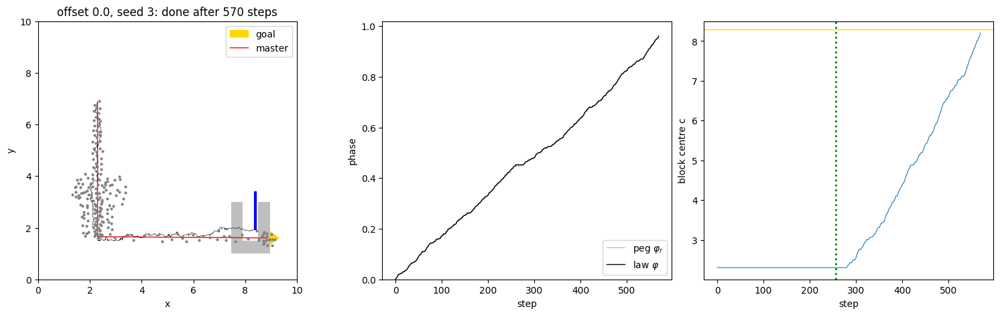

final phase 0.960, barrier removed at step 256, block at 8.20, goal 8.3
phase: phi 0.048 -> 0.052 at step 30
phase: phi 0.098 -> 0.100 at step 56
phase: phi 0.150 -> 0.152 at step 88
phase: phi 0.198 -> 0.200 at step 116
phase: phi 0.247 -> 0.250 at step 148
phase: phi 0.300 -> 0.302 at step 183
phase: phi 0.348 -> 0.350 at step 407
phase: phi 0.398 -> 0.403 at step 435
phase: phi 0.427 -> 0.458 at step 450
phase: phi 0.495 -> 0.500 at step 483
phase: phi 0.547 -> 0.550 at step 513
phase: phi 0.600 -> 0.603 at step 545
phase: phi 0.647 -> 0.650 at step 564
phase: phi 0.698 -> 0.700 at step 589
phase: phi 0.748 -> 0.750 at step 621
phase: phi 0.797 -> 0.800 at step 650
phase: phi 0.848 -> 0.853 at step 672
phase: phi 0.897 -> 0.900 at step 712
phase: phi 0.948 -> 0.953 at step 741


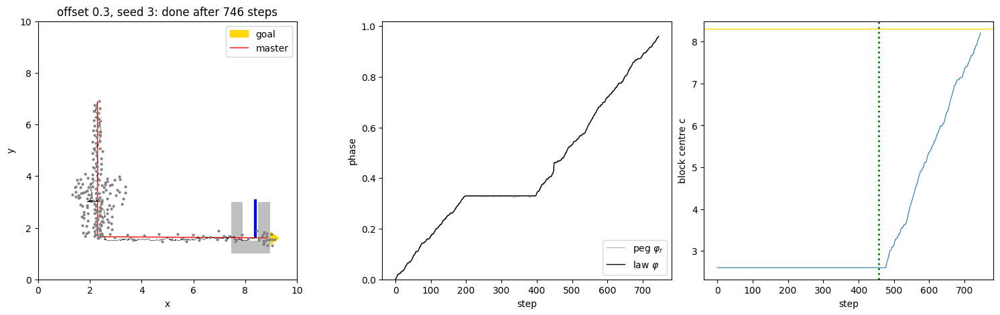

final phase 0.960, barrier removed at step 457, block at 8.21, goal 8.3
phase: phi 0.048 -> 0.052 at step 30
phase: phi 0.098 -> 0.100 at step 56
phase: phi 0.150 -> 0.152 at step 88
phase: phi 0.198 -> 0.200 at step 116
phase: phi 0.247 -> 0.250 at step 148
phase: phi 0.300 -> 0.302 at step 183
phase: phi 0.348 -> 0.350 at step 208
phase: phi 0.395 -> 0.400 at step 233
phase: phi 0.448 -> 0.450 at step 278
phase: phi 0.497 -> 0.500 at step 309
phase: phi 0.547 -> 0.550 at step 354
phase: phi 0.600 -> 0.603 at step 383
phase: phi 0.647 -> 0.650 at step 408
phase: phi 0.698 -> 0.700 at step 438
phase: phi 0.748 -> 0.750 at step 467
phase: phi 0.797 -> 0.800 at step 487
phase: phi 0.848 -> 0.850 at step 516
phase: phi 0.897 -> 0.900 at step 546
phase: phi 0.948 -> 0.950 at step 566


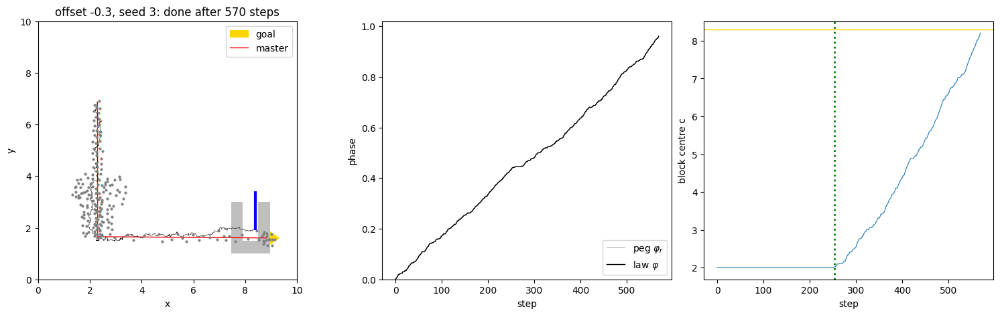

final phase 0.960, barrier removed at step 254, block at 8.21, goal 8.3


In [197]:
def show_run(offset: float, seed: int, start: tuple[float, float] | None = None) -> Run:
    run = Run(offset, seed, start).run()
    log = np.array(run.log)
    _, (world, phase, travel) = plt.subplots(
        1, 3, figsize=(15, 4.6), width_ratios=[1.2, 1, 1], layout="constrained"
    )
    draw_world(world, run.world)
    world.scatter(*CLOUD.T, zorder=3, s=4, c="0.5")
    world.plot(*MASTER.T, "-r", lw=1, label="master")
    world.plot(log[:, 0], log[:, 1], "-k", lw=0.4)
    world.plot(
        [log[-1, 0], log[-1, 0]], [log[-1, 1], log[-1, 1] + 1.5], "-b", lw=3, solid_capstyle="butt"
    )
    world.legend(loc="upper right")
    world.set_title(
        f"offset {offset}, seed {seed}: {'done' if run.done else 'not done'} after {run.n} steps"
    )
    phase.plot(log[:, 5], "-", color="0.6", lw=0.6, label=r"peg $\varphi_r$")
    phase.plot(log[:, 2], "-k", lw=1, label=r"law $\varphi$")
    phase.set(xlabel="step", ylabel="phase", ylim=(0, 1.02))
    phase.legend(loc="lower right")
    travel.plot(log[:, 3], lw=0.8)
    travel.axhline(GOAL_C, color="gold", lw=1)
    removed = int(log[:, 4].sum())  # the barrier stands on the steps before it is removed
    if removed < run.n:
        travel.axvline(removed, color="g", ls=":", lw=2)
    travel.set(xlabel="step", ylabel="block centre c")
    plt.show()
    print(
        f"final phase {run.law.phi:.3f}, barrier {'removed at step ' + str(removed) if removed < run.n else 'never removed'}, "
        f"block at {run.world.c:.2f}, goal {GOAL_C}"
    )
    return run


_ = show_run(0.0, seed=3)
offset_run = show_run(0.3, seed=3)
_ = show_run(-0.3, seed=3)

### 6.1 The offset run, animated

Left, the **target** at that step: the density the law is asked to cover, and the datapoints in it, darker the more
they weigh. Right, the **stored trajectory**: the density of the statistic, which is every past state weighted by how
much of it is still remembered, under the trail. The forgetting is exponential, not a cut-off: a state one
forgetting window old weighs $1/e$ of the newest, and the trail is drawn that much fainter. The law moves the peg to where the left exceeds the right.

In [198]:
GRID = np.linspace(0.0, 1.0, 81)  # cube coordinates of the density figures


def draw_density(ax: Axes, d: np.ndarray, cmap: str) -> None:
    ax.contourf(GRID * SIZE, GRID * SIZE, d, levels=np.linspace(0.08, 1.0, 10) * d.max(), cmap=cmap)


def draw_law(ax_target: Axes, ax_statistic: Axes, run: Run, n: int) -> None:
    """The target and the statistic of step n, each over the world as it was then."""
    log = np.array(run.log)
    x, y, phi, c, barrier, _ = log[n]
    w = run.targets[n]
    memory = np.array(run.law.memory_x[: n + 1])
    for ax in (ax_target, ax_statistic):
        ax.clear()
    draw_density(ax_target, density(to_cube(CLOUD), w, GRID), "Oranges")
    ax_target.scatter(
        *CLOUD.T, zorder=3, s=10, c=w, cmap="Greys", vmin=0, edgecolors="0.5", linewidths=0.3
    )
    v = statistic_weights(run.law, n + 1)
    draw_density(ax_statistic, density(memory, v, GRID), "Blues")
    # The trail fades as the statistic forgets: a stretch is as dark as its weight beside the newest state's.
    trail = np.stack([memory[:-1], memory[1:]], axis=1) * SIZE
    ink = np.zeros((len(trail), 4))
    ink[:, 3] = v[1:] / v[-1]
    ax_statistic.add_collection(LineCollection(trail, colors=ink, lw=0.8))
    for ax in (ax_target, ax_statistic):
        draw_world(ax, Slide(run.world.home, c, bool(barrier)))
        ax.plot(*MASTER.T, "-r", lw=0.8)
        ax.plot([x, x], [y, y + 1.5], "-b", lw=3, solid_capstyle="butt", zorder=3)
    ax_target.set_title(rf"target, step {n}: $\varphi$ = {phi:.2f}")
    ax_statistic.set_title(f"stored trajectory: 1/e at {FORGET_WINDOW:.0f} steps back")


def animate_run(run: Run) -> FuncAnimation:
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), dpi=60, layout="constrained")
    frames = [*range(0, run.n, max(1, run.n // 150)), run.n - 1]
    anim = FuncAnimation(fig, lambda n: draw_law(*axes, run, n), frames=frames, interval=80)
    plt.close(fig)
    return anim


plt.rcParams["animation.embed_limit"] = 100
display(HTML(animate_run(offset_run).to_jshtml()))

## 7. A failure: beside the hole, at the barrier

The peg has missed the slot, come down between the block and the barrier, and followed the master's line towards the
goal as far as the barrier. That stretch of the master runs through here, so the phase is as far along as the peg.
The barrier stands, since the peg was never in the slot, and the target's newest slice lies behind it.

The run is started in that state (Section 5). What has to happen: the peg leaves the barrier, goes **back** to places of
earlier phase, finds the slot, removes the barrier from inside it and then carries the block to the goal. In the phase
panel that is $\varphi_r$ falling below $\varphi$ and coming back up.

phase: phi 0.600 -> 0.603 at step 1895
phase: phi 0.647 -> 0.650 at step 1923
phase: phi 0.698 -> 0.700 at step 1957
phase: phi 0.748 -> 0.753 at step 1985
phase: phi 0.797 -> 0.800 at step 2014
phase: phi 0.848 -> 0.850 at step 2044
phase: phi 0.897 -> 0.900 at step 2072
phase: phi 0.948 -> 0.950 at step 2105


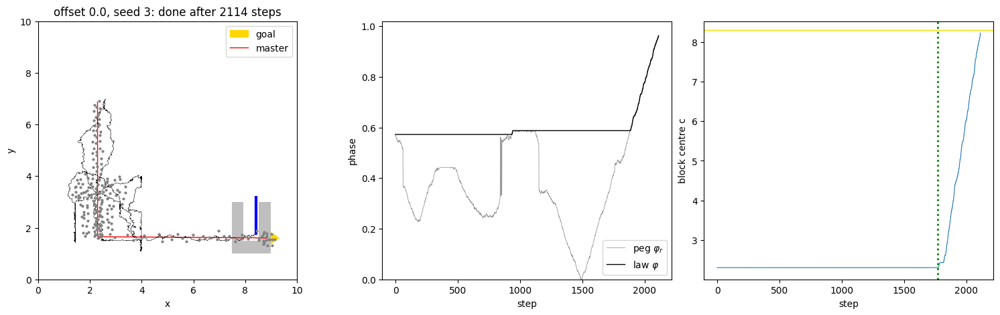

final phase 0.963, barrier removed at step 1768, block at 8.23, goal 8.3
started at phi = 0.57; the peg went back as far as phi_r = 0.00 (step 1489)


In [199]:
STUCK = (
    BARRIER_X - 0.2,
    float(MASTER[:, 1].min()),
)  # at the barrier, at the height the master slides at

stuck_run = show_run(0.0, seed=3, start=STUCK)
_log = np.array(stuck_run.log)
print(
    f"started at phi = {_log[0, 2]:.2f}; the peg went back as far as phi_r = {_log[:, 5].min():.2f} "
    f"(step {_log[:, 5].argmin()})"
)
display(HTML(animate_run(stuck_run).to_jshtml()))

In [200]:
print(" seed   done  steps  barrier removed at  lowest phi_r")
for seed in range(3, 8):
    run = Run(0.0, seed, start=STUCK).run()
    log = np.array(run.log)
    removed = int(log[:, 4].sum())
    print(
        f"{seed:>5}  {'yes' if run.done else 'no':>5}  {run.n:>5}  "
        f"{removed if removed < run.n else 'never':>18}  {log[:, 5].min():>12.2f}"
    )

 seed   done  steps  barrier removed at  lowest phi_r
phase: phi 0.600 -> 0.603 at step 1895
phase: phi 0.647 -> 0.650 at step 1923
phase: phi 0.698 -> 0.700 at step 1957
phase: phi 0.748 -> 0.753 at step 1985
phase: phi 0.797 -> 0.800 at step 2014
phase: phi 0.848 -> 0.850 at step 2044
phase: phi 0.897 -> 0.900 at step 2072
phase: phi 0.948 -> 0.950 at step 2105
    3    yes   2114                1768          0.00
phase: phi 0.600 -> 0.603 at step 463
phase: phi 0.647 -> 0.650 at step 486
phase: phi 0.698 -> 0.700 at step 523
phase: phi 0.748 -> 0.750 at step 544
phase: phi 0.797 -> 0.800 at step 573
phase: phi 0.848 -> 0.850 at step 605
phase: phi 0.897 -> 0.900 at step 630
phase: phi 0.948 -> 0.953 at step 668
    4    yes    675                 399          0.22
phase: phi 0.600 -> 0.605 at step 1840
phase: phi 0.645 -> 0.650 at step 1872
phase: phi 0.698 -> 0.700 at step 1899
phase: phi 0.745 -> 0.750 at step 1926
phase: phi 0.797 -> 0.802 at step 1954
phase: phi 0.848 -> 0.850 a

## 8. Trials with a permanent memory of negative progress

The arm's law is extended here, in the notebook only, to test one idea before it goes into `phase_ergodic_controller.py`.
It is a map of the environment made without a sensor: the only signal is the phase.

**Tracked phase.** $\varphi_t$ follows the peg along the master, moving at most one master sample a step, 1/400 of
the master's length. Unlike the nearest sample over the whole master, it cannot jump from one stretch to another.

**Sustained retreat.** $\varphi_t$ is at least $3\sigma_f$ lower than it was 50 steps before. At one sample a step
that fall takes most of the period, so it is a peg that kept going back, not one that stepped aside.

**What is stored.** Where the peg was before the retreat began: the 50 states up to the last step at which
$\varphi_t$ was at its highest in that period. They become **permanent**. The detection is then off until
$\varphi_t$ has risen $\sigma_f$ above its lowest since, so one retreat stores one place.

**Permanent** states stay in the statistic with the weight of a state just stored, 1, where the others have
$\text{keep}^{\text{age}}$; the statistic keeps mass 1. They are not forgotten, and they are handed to the next trial.

**A trial** starts the law over at the master's start, as `run_ergodic_expanding_trials.py` does: $\varphi = 0$ and the
forgetting memory emptied. With this memory, only the permanent states are carried over.

**The full distribution** is the second baseline: the same law with every datapoint in the target from the first step,
equally weighted, so nothing expands. Its phase is still estimated, for the goal.

In [201]:
RETREAT_PERIOD = 50  # steps
RETREAT_DROP = 3.0  # in sigma_f


class NegativeProgressController(ExpandingErgodicController):
    """The arm's law, with the place a sustained retreat began at kept for good."""

    def __init__(self, kept: np.ndarray):  # (D, 2) cube states that earlier trials made permanent
        super().__init__(TASK, V_MAX / SIZE, FORGET_WINDOW, FRONT_SHARE, K)
        self.memory_x = list(kept)
        self.memory_phi = [0.0] * len(kept)
        self.permanent = [True] * len(kept)  # per stored state
        self.marked_at = [0] * len(kept)  # the step of this trial a state became permanent at
        self.carried = len(kept)  # this trial's states follow these in the memory
        self.sample = 0  # the master sample the tracked phase is at
        self.tracked: list[float] = []  # the tracked phase, per step of this trial
        self.armed, self.lowest = True, 0.0

    def step(self, x_measured: np.ndarray, dt: float) -> np.ndarray:
        x_next = super().step(x_measured, dt)
        self.permanent.append(False)
        self.marked_at.append(-1)
        near = slice(max(0, self.sample - 1), self.sample + 2)
        d2 = ((MASTER[near] - np.asarray(x_measured) * SIZE) ** 2).sum(axis=1)
        self.sample = near.start + int(d2.argmin())
        self.tracked.append(float(PHI_GRID[self.sample]))
        self._store_retreat()
        return x_next

    def _store_retreat(self) -> None:
        n, phi_t = len(self.tracked), self.tracked[-1]
        if not self.armed:
            self.lowest = min(self.lowest, phi_t)
            self.armed = phi_t >= self.lowest + SIGMA_F
            return
        period = np.array(self.tracked[max(0, n - 1 - RETREAT_PERIOD) :])
        if period[0] - phi_t < RETREAT_DROP * SIGMA_F:
            return
        began = n - len(period) + int(np.nonzero(period == period.max())[0][-1])
        for i in range(self.carried + max(0, began - RETREAT_PERIOD), self.carried + began + 1):
            if not self.permanent[i]:
                self.permanent[i], self.marked_at[i] = True, n - 1
        self.armed, self.lowest = False, phi_t

    def point_weights(self) -> tuple[np.ndarray, float]:
        a, sigma_b = super().point_weights()
        n = len(self.memory_x)
        permanent = np.zeros(n, dtype=bool)  # the newest state is stored before it is flagged
        permanent[: len(self.permanent)] = self.permanent
        v = np.where(permanent, 1.0, self.keep ** np.arange(n - 1, -1, -1))
        a[self._fixed :] = v / v.sum()
        return a, sigma_b

    def kept(self) -> np.ndarray:  # (D, 2) cube states
        return np.array(self.memory_x).reshape(-1, 2)[self.permanent]


class FullTargetController(ExpandingErgodicController):
    """The arm's law on the whole taught distribution at once: no expansion, no front share."""

    def point_weights(self) -> tuple[np.ndarray, float]:
        a, sigma_b = super().point_weights()
        n = len(self.task.X)
        self.target_weights = np.full(n, 1.0 / n)
        a[:n] = -self.target_weights
        return a, sigma_b


# A peg that follows the master to sample 120, stands there, and then goes back 4 sigma_f, a sample a step.
_law = NegativeProgressController(np.empty((0, 2)))
_back = math.ceil(4 * SIGMA_F * 400)
with contextlib.redirect_stdout(io.StringIO()):
    for _i in [*range(120), *[120] * 30]:
        _law.step(to_cube(MASTER[_i]), 1.0)
    assert not any(_law.permanent)  # progress, and standing still, store nothing for good
    for _i in range(119, 119 - _back, -1):
        _law.step(to_cube(MASTER[_i]), 1.0)
# What is kept is the period up to the last step before the retreat: not the way there, not the way back.
assert (
    all(_law.permanent[100:150]) and not any(_law.permanent[:99]) and not any(_law.permanent[150:])
)
# It was stored once the peg had gone back 3 sigma_f, no sooner.
assert set(_law.marked_at[100:150]) == {149 + math.ceil(RETREAT_DROP * SIGMA_F * 400)}
# The tracked phase cannot jump: put at the master's end, it moves one sample.
_sample = _law.sample
with contextlib.redirect_stdout(io.StringIO()):
    _law.step(to_cube(MASTER[-1]), 1.0)
assert _law.sample == _sample + 1
# Permanent states weigh alike and most, and the statistic has mass 1.
_v = _law.point_weights()[0][_law._fixed :]
assert math.isclose(_v.sum(), 1.0) and np.allclose(_v[100:150], _v.max()) and _v[0] < _v.max()
# They are what the next trial starts with.
_next = NegativeProgressController(_law.kept())
assert len(_next.memory_x) == sum(_law.permanent) and all(_next.permanent)
# The full target weighs every datapoint alike, whatever the phase.
_full = FullTargetController(TASK, V_MAX / SIZE, FORGET_WINDOW, FRONT_SHARE, K)
with contextlib.redirect_stdout(io.StringIO()):
    _full.step(to_cube(MASTER[0]), 1.0)
assert np.allclose(_full.point_weights()[0][: len(CLOUD)], -1 / len(CLOUD))
print(f"retreat tests passed: {sum(_law.permanent)} states made permanent")

retreat tests passed: 51 states made permanent


### 8.1 The assessment

The block starts 0.7 short of where it was taught. The master's way down then lands on the block's top beside the
slot, and most trials slide off it, come down between the block and the barrier and run on to the barrier.

48 sequences of six trials for each of three methods, on the same noise:

- **expanding**: the arm's law, every trial independent;
- **memory**: the same with the memory of retreats handed from trial to trial;
- **full**: the full distribution, every trial independent.

A trial is a **success** when the peg and the block are both at the goal, and counts as the full 5000 steps when it
is not. **At the barrier** is a trial in which the peg was beside the block, before the barrier, while it stood.

The sequences run in parallel, one process a core.

48 sequences of 6 trials a method; per trial, the mean over the sequences

expanding
           success   0.94   0.98   0.96   0.94   1.00   0.96
    at the barrier   0.75   0.75   0.75   0.77   0.73   0.73
             steps   1594   1553   1702   1647   1546   1422
  permanent states      0      0      0      0      0      0
   trials 2 to 6: success 0.97, at the barrier 0.75, steps 1574 +- 71 (median 1264)

memory
           success   0.94   0.96   1.00   0.98   1.00   1.00
    at the barrier   0.75   0.42   0.46   0.29   0.17   0.17
             steps   1668   1360   1264   1091   1153   1055
  permanent states     52     86    112    130    146    155
   trials 2 to 6: success 0.99, at the barrier 0.30, steps 1184 +- 47 (median 853)

full
           success   0.58   0.54   0.69   0.69   0.73   0.81
    at the barrier   0.94   0.92   0.94   0.90   0.94   0.94
             steps   3701   3989   3604   3260   3406   3137
  permanent states      0      0      0      0      0      0
  

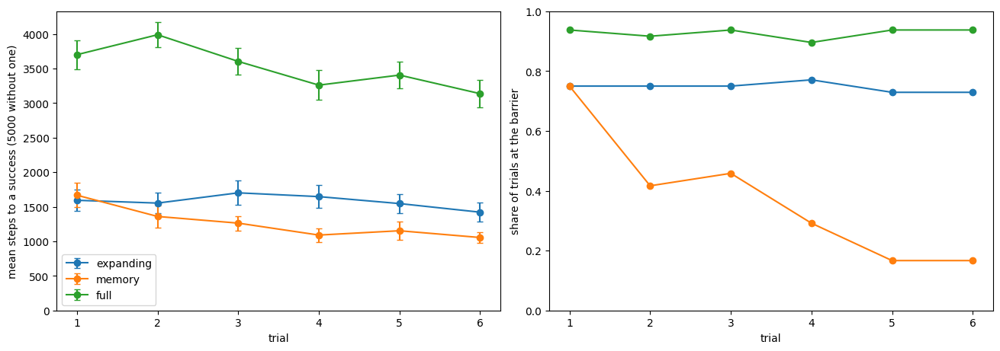

In [202]:
MISS_OFFSET, N_TRIALS, N_SEQUENCES = -0.7, 6, 48
METHODS = ("expanding", "memory", "full")


def run_trials(method: str, seed: int) -> list[Run]:
    """The N_TRIALS trials of one sequence."""
    kept, runs = np.empty((0, 2)), []
    for trial in range(N_TRIALS):
        law = None
        if method == "memory":
            law = NegativeProgressController(kept)
        elif method == "full":
            law = FullTargetController(TASK, V_MAX / SIZE, FORGET_WINDOW, FRONT_SHARE, K)
        with contextlib.redirect_stdout(io.StringIO()):  # the law's progress lines
            runs.append(Run(MISS_OFFSET, 100 * seed + trial, law=law).run())
        if method == "memory":
            kept = law.kept()
    return runs


def score(job: tuple[str, int]) -> list[tuple[int, bool, bool, int]]:
    """Per trial of one sequence: steps, success, at the barrier, permanent states."""
    rows = []
    for run in run_trials(*job):
        x, y, _, c, barrier, _ = np.array(run.log).T
        beside = (barrier > 0) & (x > c + BLOCK_HALF + PEG_HALF) & (x < BARRIER_X) & (y < BLOCK_TOP)
        rows.append((run.n, run.done, beside.any(), sum(getattr(run.law, "permanent", []))))
    return rows


_jobs = [(method, seed) for method in METHODS for seed in range(N_SEQUENCES)]
with ProcessPoolExecutor(mp_context=multiprocessing.get_context("fork")) as pool:
    _scores = np.array(list(pool.map(score, _jobs)), dtype=float)
# (method, sequence, trial) each
STEPS_TAKEN, SUCCESS, AT_BARRIER, PERMANENT = np.moveaxis(
    _scores.reshape(len(METHODS), N_SEQUENCES, N_TRIALS, 4), -1, 0
)

print(
    f"{N_SEQUENCES} sequences of {N_TRIALS} trials a method; per trial, the mean over the sequences\n"
)
for m, method in enumerate(METHODS):
    print(method)
    for label, values, form in (
        ("success", SUCCESS, ".2f"),
        ("at the barrier", AT_BARRIER, ".2f"),
        ("steps", STEPS_TAKEN, ".0f"),
        ("permanent states", PERMANENT, ".0f"),
    ):
        print(f"{label:>18}" + "".join(f"{v:>7{form}}" for v in values[m].mean(axis=0)))
    later = STEPS_TAKEN[m, :, 1:]
    error = later.mean(axis=1).std(ddof=1) / math.sqrt(
        N_SEQUENCES
    )  # the sequences are the independent units
    print(
        f"   trials 2 to {N_TRIALS}: success {SUCCESS[m, :, 1:].mean():.2f}, "
        f"at the barrier {AT_BARRIER[m, :, 1:].mean():.2f}, "
        f"steps {later.mean():.0f} +- {error:.0f} (median {np.median(later):.0f})\n"
    )

fig, (steps, barrier) = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
trials = np.arange(1, N_TRIALS + 1)
for m, method in enumerate(METHODS):
    mean = STEPS_TAKEN[m].mean(axis=0)
    error = STEPS_TAKEN[m].std(axis=0, ddof=1) / math.sqrt(N_SEQUENCES)
    steps.errorbar(trials, mean, error, marker="o", capsize=3, label=method)
    barrier.plot(trials, AT_BARRIER[m].mean(axis=0), "o-", label=method)
steps.set(xlabel="trial", ylabel="mean steps to a success (5000 without one)", ylim=(0, None))
barrier.set(xlabel="trial", ylabel="share of trials at the barrier", ylim=(0, 1))
steps.legend()
plt.show()

### 8.2 What a sequence stored for good, as it happened

One sequence with the memory, run again here, its trials one after the other. Black: this trial's path so far. Red: the states this
trial has made permanent up to this step. Purple: the permanent states it was handed by the trials before it.

In [203]:
def animate_trials(runs: list[Run]) -> FuncAnimation:
    """The trials of one remembering sequence, about 60 frames each."""
    fig, ax = plt.subplots(figsize=(7, 7), dpi=60, layout="constrained")
    frames = [
        (trial, n)
        for trial, run in enumerate(runs)
        for n in [*range(0, run.n, max(1, run.n // 60)), run.n - 1]
    ]

    def update(frame: tuple[int, int]) -> None:
        trial, n = frame
        run, law = runs[trial], runs[trial].law
        x, y, _, c, barrier, _ = run.log[n]
        memory = np.array(law.memory_x) * SIZE
        marked = np.array(law.marked_at)
        new = (marked >= 0) & (marked <= n)
        new[: law.carried] = False
        ax.clear()
        draw_world(ax, Slide(run.world.home, c, bool(barrier)))
        ax.scatter(*CLOUD.T, zorder=3, s=4, c="0.7")
        ax.plot(*MASTER.T, "-r", lw=0.8)
        ax.plot(*memory[law.carried : law.carried + n + 1].T, "-k", lw=0.4, zorder=3)
        ax.plot(
            *memory[: law.carried].T,
            ".",
            color="purple",
            ms=4,
            zorder=4,
            label="from earlier trials",
        )
        ax.plot(
            *memory[new].T, ".", color="red", ms=4, zorder=4, label="stored for good in this trial"
        )
        ax.plot([x, x], [y, y + 1.5], "-b", lw=3, solid_capstyle="butt", zorder=5)
        ax.legend(loc="upper right")
        ax.set_title(
            f"trial {trial + 1}, step {n}: {law.carried} handed over, {new.sum()} stored for good in this trial"
        )

    anim = FuncAnimation(fig, update, frames=frames, interval=80)
    plt.close(fig)
    return anim


remembering_runs = run_trials("memory", 0)  # the first sequence of the assessment
display(HTML(animate_trials(remembering_runs).to_jshtml()))

## 9. The algorithm, step by step

Everything above, as formulas. Sections 9.1 to 9.3 are the arm's law (`ExpandingErgodicController`), 9.4 the plant of
this notebook, 9.5 and 9.6 the memory of retreats and the trials (Section 8).

### 9.1 What is taught, and what is derived from it

- **State.** The peg tip $s = (x, y) \in [0, L]^2$ with $L = 10$; the law works in the cube, $z = s / L \in [0, 1]^2$.
- **Master.** The clicked polyline of length $\ell$, resampled at equal arc length to $M_i$, $i = 0, \dots, 400$, with
  phase $\varphi_i = i / 400$.
- **Datapoints.** The clicks $p_j$, $j = 1, \dots, N$, each labelled with the phase of its nearest master sample,
  $\varphi_j = \varphi_{i^*}$, $i^* = \arg\min_i \lVert p_j - M_i \rVert$.
- **Resolution.** $h = \operatorname{median}_j\, \lVert p_j - p_{j,(k)} \rVert$, the distance to the $k$-th nearest
  datapoint, $k = \operatorname{round}(\sqrt N)$; as a phase, $\sigma_f = h / \ell$.
- **Forgetting.** $T_f = 75\, h / v_{\max}$ steps, and $\kappa = 1 - 1 / T_f$.

### 9.2 The phase, each step

With the law's phase $\varphi$ (0 at the start of a trial) and the measured state $s_n$:

$$\hat\varphi = \varphi_{i^*}, \qquad i^* = \arg\min_{i\,:\ \varphi - 0.05\ \le\ \varphi_i\ \le\ \varphi + 0.12} \lVert M_i - s_n \rVert .$$

$\hat\varphi$ is accepted, $\varphi \leftarrow \hat\varphi$, only if it is an advance **on the reference**:

$$\hat\varphi > \varphi \quad\text{and}\quad \exists\, q \in \{p_j\} \cup \{M_i\}:\ \ \lvert \varphi_q - \hat\varphi \rvert \le \sigma_f\ \text{ and }\ \lVert q - s_n \rVert \le h .$$

So $\varphi$ never decreases, and it does not advance at a place nothing was taught at for that phase.

### 9.3 The ergodic step

**Basis.** $\Phi_{\mathbf k}(z) = \cos(\pi k_1 z_1) \cos(\pi k_2 z_2)$ for $\mathbf k \in \{0, \dots, K - 1\}^2$, $K = 10$, with
weights $\Lambda_{\mathbf k} = (1 + \lVert \mathbf k \rVert^2)^{-3/2}$ (held as a tensor train rounded to $10^{-2}$, as on the arm).

**Target.** With $d_j = \varphi_j - \min(1, \varphi + \sigma_f)$:

$$r_j = \begin{cases} 1 & d_j \le 0 \\ e^{-d_j^2 / 2\sigma_f^2} & d_j > 0 \end{cases} \qquad f_j = e^{-d_j^2 / 2\sigma_f^2} \qquad w_j = 0.75\, \frac{r_j}{\sum_i r_i} + 0.25\, \frac{f_j}{\sum_i f_i}, \qquad \hat{\mathcal W}_{\mathbf k} = \sum_j w_j\, \Phi_{\mathbf k}(p_j / L) .$$

$r$ is everything reached so far, $f$ the newest slice alone. For the **full-distribution** baseline, $w_j = 1 / N$ instead.

**Statistic.** Every measured state is stored. With $\mathcal P$ the permanent states (Section 9.5; empty for the arm's law):

$$v_m = \frac{\tilde v_m}{\sum_i \tilde v_i}, \qquad \tilde v_m = \begin{cases} 1 & z_m \in \mathcal P \\ \kappa^{\,n - m} & \text{otherwise} \end{cases} \qquad \mathcal W_{\mathbf k} = \sum_{m \le n} v_m\, \Phi_{\mathbf k}(z_m) .$$

Both $\hat{\mathcal W}$ and $\mathcal W$ have mass 1 ($\hat{\mathcal W}_{\mathbf 0} = \mathcal W_{\mathbf 0} = 1$).

**Direction.**

$$b_i = \sum_{\mathbf k} \Lambda_{\mathbf k} \big( \mathcal W_{\mathbf k} - \hat{\mathcal W}_{\mathbf k} \big)\, \frac{\partial \Phi_{\mathbf k}}{\partial z_i}(z_n), \qquad u^{\text{erg}} = -\frac{b}{\lVert b \rVert} .$$

**Cube faces.** Per axis, with $\alpha = 20$ and $c = 1/20$:

$$\omega_i = \tfrac12 \tanh\!\big(\alpha (z_i - c)\big) + \tfrac12 \tanh\!\big(\alpha (1 - c - z_i)\big), \qquad g_i = -\tfrac12 \tanh\!\big(\alpha (z_i - c)\big) + \tfrac12 \tanh\!\big(\alpha (1 - c - z_i)\big),$$

$$u = \omega \odot u^{\text{erg}} + (1 - \omega) \odot \frac{g}{\lVert g \rVert}, \qquad z^{\text{cmd}} = \operatorname{clip}\!\Big( z_n + \frac{v_{\max}}{L} \frac{u}{\lVert u \rVert},\ 0,\ 1 \Big) .$$

### 9.4 The plant

$$\Delta = L\,(z^{\text{cmd}} - z_n) + \eta, \quad \eta \sim \mathcal U(-0.07, 0.07)^2, \qquad \Delta \leftarrow \Delta \min\!\Big(1, \frac{v_{\max}}{\lVert \Delta \rVert}\Big), \qquad s_{n+1} = \mathcal E(s_n,\ s_n + \Delta) .$$

$\mathcal E$ is the environment of Section 2: the block stops the tip, the barrier stops the tip and the block, the
barrier is removed once the tip is at the slot's bottom, and a tip in the slot pushes the block.

### 9.5 The memory of retreats

**Tracked phase.** A master index $i_n$ that moves at most one sample a step, $i_0 = 0$:

$$i_n = \arg\min_{i \in \{i_{n-1} - 1,\ i_{n-1},\ i_{n-1} + 1\}} \lVert M_i - s_n \rVert, \qquad \varphi^t_n = i_n / 400 .$$

**Sustained retreat.** While the detection is armed, with $P = 50$ steps and $D = 3$:

$$\varphi^t_{n - P} - \varphi^t_n \ \ge\ D\, \sigma_f .$$

**Where it began.** The last step of that period at which the tracked phase was highest:

$$n^* = \max \Big\{ m \in [n - P,\ n] : \varphi^t_m = \max_{n - P \le i \le n} \varphi^t_i \Big\} .$$

**What is stored.** The period before it:

$$\mathcal P \leftarrow \mathcal P \cup \{ z_m : n^* - P \le m \le n^* \} .$$

**Re-arming.** The detection is switched off with $\varphi^{\text{low}} = \varphi^t_n$. While off,
$\varphi^{\text{low}} \leftarrow \min(\varphi^{\text{low}}, \varphi^t_n)$, and it is armed again once
$\varphi^t_n \ge \varphi^{\text{low}} + \sigma_f$.

$\mathcal P$ enters the law only through $\tilde v_m = 1$ in the statistic of Section 9.3: those places count as
covered, at the weight of a state just stored, and are never discounted.

### 9.6 Trials, and the goal

At the start of a trial the peg is at $M_0$ and

$$\varphi \leftarrow 0, \qquad i_0 \leftarrow 0, \qquad \text{memory} \leftarrow \mathcal P, \qquad \text{detection armed} .$$

So a trial inherits the permanent states and nothing else. The two baselines start every trial with an empty memory.

A trial ends, as a success, at the first step with the peg and the block's centre $c$ both at the goal,

$$x_n > x_g \quad\text{and}\quad c_n > x_g, \qquad x_g = 8.2,$$

or after 5000 steps without one.

### 9.7 The numbers

| symbol | value | set by |
|---|---|---|
| $K$ | 10 | the arm (`ERGODIC_K`) |
| front share | 0.25 | the arm (`run_ergodic_expanding.py`) |
| $T_f$ | $75\, h / v_{\max}$ | the arm (`FORGET_PROGRESS`) |
| phase window | $[-0.05,\ +0.12]$ | the arm (`PHASE_WINDOW`) |
| $h$, $\sigma_f$, on-reference distance $h$ | from the clicks | the data |
| $v_{\max}$, noise | 0.04, $\pm 0.07$ a step | this notebook's plant |
| $P$, $D$ | 50 steps, 3 | the memory, chosen |
| tracker speed, re-arm rise | 1 sample a step, $\sigma_f$ | the memory, chosen |
| $x_g$ | 8.2 | the goal, chosen |